## **Funções**

### Importação das Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import unicodedata 

### Função para realizar a normalização dos nomes das cidades para caixa alta e sem acento

In [2]:
def normalizar_texto(texto):

    if not isinstance(texto, str):
        return ""
    
    # Separa os acentos das letras
    texto_normalizado = unicodedata.normalize('NFKD', texto)

    # Conversão para ASCII ignorando os acentos
    texto_ascii = texto_normalizado.encode('ASCII', 'ignore').decode('ASCII')

    #Transformação das letras em maiúsculas
    texto = texto_ascii.upper().strip()

    return texto

### Função para leitura das bases de dados SISVAN

In [5]:
def leitura_dados_sisvan(uf, pasta_origem=".", anos = [2020, 2021, 2022, 2023, 2024, 2025]):

    lista_dfs = []

    colunas_qtd = [ 'Baixo peso','Adequado','Sobrepeso', 'Obesidade Grau I', 'Obesidade Grau II', 'Obesidade Grau III', 'Total']

    colunas_porcentagem = ['Obesidade Grau I %', 'Obesidade Grau II %', 'Obesidade Grau III %']

    for ano in anos:
        # Leitura dos arquivos em excel

        caminho = os.path.join(pasta_origem, f'RelatorioEstadoNutricional {ano} {uf}.xls.xlsx')

        if not os.path.exists(caminho):
            print(f'Aviso: Ficheiro não encontrado -> {caminho}')
            continue

        df_ano = pd.read_excel(caminho, header=1)

        # Remove espaços em branco antes e depois do nome de todas as colunas
        df_ano.columns = df_ano.columns.astype(str).str.strip()

        # Acrescenta a coluna do ano da base de dados
        df_ano['ano'] = ano

        # Cria a coluna municipio_norm e aplica a normalização no nome dos municípios
        df_ano['municipio_norm'] = df_ano['Município'].apply(normalizar_texto)

        # Altera o tipo de dados das colunas de quantidades para numérico

        for coluna in colunas_qtd:
            df_ano[coluna] = pd.to_numeric(df_ano[coluna], errors='coerce')


        # Tratamento da coluna de dados que possuem o símbolo de porcentagem nas células
        
        for coluna in colunas_porcentagem:
            # Tipo da coluna é string
            df_ano[coluna] = df_ano[coluna].astype(str)

            # Remoção do símbolo de porcentagem
            df_ano[coluna] = df_ano[coluna].str.replace('%', '', regex=False).str.replace(',', '.', regex=False).str.strip()

            # Conversão para float
            df_ano[coluna] = pd.to_numeric(df_ano[coluna], errors='coerce')

            # Verifica se há alguma célula fora do padrão de 100%
            condicao = (df_ano[coluna] > 0) & (df_ano[coluna] <= 1)

            df_ano.loc[condicao, coluna] = df_ano[coluna] * 100

            df_ano[coluna] = df_ano[coluna].round(2)

        # Cria colunas com o valor total de obesidade por cidade e taxa de obesidade
        
        df_ano['obesidade_total'] = df_ano['Obesidade Grau I'] + df_ano['Obesidade Grau II'] + df_ano['Obesidade Grau III']

        df_ano['obesidade_total_%'] = ((df_ano['obesidade_total'] / df_ano['Total']) * 100).round(2)

        lista_dfs.append(df_ano)

    return pd.concat(lista_dfs, ignore_index=True)

### Função para leitura de dados do IDHM

In [6]:
def leitura_idhm(uf, pasta_origem = '5 - IDHM'):

    caminho_idhm = os.path.join(pasta_origem,f'IDHM - {uf}.xlsx')
    df_idhm = pd.read_excel(caminho_idhm)

    # Tratamento e normalização dos nomes dos municípios
    df_idhm['municipio_norm'] = df_idhm['Municípios'].apply(normalizar_texto)

    # Mudança do tipo de dados da coluna IDHM para numérico
    df_idhm['idhm_2010'] = pd.to_numeric(df_idhm['Índice de Desenvolvimento Humano Municipal (IDHM)'], errors='coerce')

    # Categorização nas faixas do PNUD
    faixas = [0.0, 0.499, 0.599, 0.699, 0.799, 1.0]
    rotulos = ['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto']

    df_idhm['faixa_idhm'] = pd.cut(df_idhm['idhm_2010'], bins=faixas, labels=rotulos)

    return df_idhm

### Função para selecionar as colunas dos dados SISVAN que serão utilizadas no merge entre SISVAN e IDHM

In [7]:
def selecionar_colunas_merge(df):

    colunas_desejadas = ['ano', 'UF', 'Código IBGE','municipio_norm', 'Baixo peso', 'Adequado', 'Sobrepeso', 'Obesidade Grau I', 'Obesidade Grau II', 'Obesidade Grau III', 'Total', 'obesidade_total', 'obesidade_total_%', 'Obesidade Grau I %', 'Obesidade Grau II %', 'Obesidade Grau III %',]

    df_sisvan_limpo = df[colunas_desejadas].copy()

    return df_sisvan_limpo


### Função para leitura de valores zerados

In [ ]:
def identificar_valores_zerados(df, coluna):

    df_zerados = df[df[coluna] == 0].copy()

    return df_zerados

### Função para leitura de valores nulos

In [ ]:
def identificar_valores_nulos(df, coluna):
    
    df_nulos = df[df [coluna].isna()].copy()

    return df_nulos

### Função para fazer o cruzamentos de dados entre SISVAN e IDHM

In [11]:
def integrar_sisvan_idhm(df_sisvan, df_idhm):
    df_integrado = pd.merge(
        df_sisvan,
        df_idhm[['municipio_norm', 'idhm_2010', 'faixa_idhm']],
        on='municipio_norm',
        how = 'inner'
    )
    return df_integrado

### Função para verificar o número de municípios em cada faixa de IDHM (como o IDHM é de 2010 a faixa é igual para todos os anos)

In [12]:
def municipios_por_faixa_IDHM(df):

    contagem_df = (df.groupby(['faixa_idhm'])['municipio_norm'].nunique().reset_index())

    contagem_df.columns = ['Faixa de IDHM', 'Qtd Municípios']

    return contagem_df

### Função para análise exploratória agregada no período 2020-2025

In [13]:
def comparar_idhm (df):
  
    comparacao_idhm = df.groupby('faixa_idhm').agg(
        qtd_municipios=('municipio_norm', 'nunique'),
        qtd_observacoes=('municipio_norm', 'count'),
        media_obesidade=('obesidade_total_%', 'mean'),
        mediana_obesidade=('obesidade_total_%', 'median'),
        desvio_obesidade =('obesidade_total_%', 'std'),
        maximo_obesidade =('obesidade_total_%', 'max'),
        minimo_obesidade =('obesidade_total_%', 'min')

    ).round(2).reset_index()


    # Exibe o resultado formatado
    comparacao_idhm = comparacao_idhm.rename(columns={
        'faixa_idhm': 'Faixa do IDHM',
        'qtd_municipios': 'Número de Municípios',
        'qtd_observacoes': 'Número de observações (2020-2025)',
        'media_obesidade': 'Média da Taxa de Obesidade (%)',
        'mediana_obesidade': 'Mediana da Taxa de Obesidade (%)', 
        'desvio_obesidade': 'Desvio-padrão da Taxa de Obesidade (%)',
        'maximo_obesidade': 'Valor máximo da Taxa de Obesidade (%)',
        'minimo_obesidade': 'Valor mínimo da Taxa de Obesidade (%)'
    })

    return comparacao_idhm

### Função para analisar a Média Anual da Taxa de Obesidade em cada Faixa de IDHM

In [14]:
def media_anual_obesidade(df):
    evolucao_anual = df.groupby(['faixa_idhm', 'ano'])['obesidade_total_%'].mean().unstack()

    # Arredonda para 2 casas decimais
    return evolucao_anual.round(2)

### Função para analisar a Mediana Anual da Taxa de Obesidade em cada Faixa de IDHM

In [15]:
def mediana_anual_obesidade(df):
    evolucao_anual_mediana = df.groupby(['faixa_idhm', 'ano'])['obesidade_total_%'].median().unstack()

    # Arredonda para 2 casas decimais
    return evolucao_anual_mediana.round(2)

### Função para criar o Gráfico de Dispersão IDHM x Obesidade

In [16]:
def grafico_IDHM_Obesidade(df, uf):

    df_municipio = (df.groupby(['municipio_norm', 'idhm_2010'])['obesidade_total_%'].mean().reset_index())

    # Seleção e remoção de valores nulos das colunas
    df_valido = df_municipio[['idhm_2010', 'obesidade_total_%']].dropna()

    x = df_valido['idhm_2010']
    y = df_valido['obesidade_total_%']

    #  Cálculo da linha de tendência 
    m, b = np.polyfit(x, y, 1)

    # Construção do gráfico com Matplotlib
    plt.figure(figsize=(7, 4))

    # Ponto de dispersão
    plt.scatter(x, y, alpha=0.4, color="#1b8bdb", label='Municípios')

    # Linha de tendência
    plt.plot(x, m * x + b, color='red', linewidth=2, label=f'Tendência')

    # Plotagem do gráfico
    plt.title(f'Dispersão: IDHM (2010) vs. Taxa de Obesidade (%) - {uf}', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('IDHM (2010)', fontsize=11)
    plt.ylabel('Taxa de Obesidade (%)', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.legend(
        title='Legenda',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        borderaxespad=0,
    )

    plt.tight_layout()
    plt.show()

### Função para analisar a média da Taxa de Obesidade a partir dos Graus em cada Faixa de IDHM  2020 - 2025

In [17]:
def analise_por_grau_obesidade(df, uf):
    grupo_grau_de_obesidade = df.groupby('faixa_idhm')[['Obesidade Grau I %', 'Obesidade Grau II %','Obesidade Grau III %']].mean().round(2)

    return grupo_grau_de_obesidade.style.format("{:.2f}").set_caption(f"Evolução Média dos Graus de Obesidade (%) por Faixa de IDHM (2020-2025) {uf}").set_table_styles([{'selector': 'caption', 'props': [('font-weight', 'bold'), ('font-size', '11pt')]}])

### Função para analisar a evolução anual de um Grau específico de obesidade em relação as faixas de IDHM

In [18]:
def evolucao_anual_grau(df, coluna, uf):
    evolucao_anual_GrauI = df.groupby(['faixa_idhm', 'ano'])[coluna].mean().unstack()

    return evolucao_anual_GrauI.style.format("{:.2f}").set_caption(f"Evolução da {coluna} por Faixa de IDHM {uf}").set_table_styles([{'selector': 'caption','props':[('font-weight', 'bold'), ('font-size', '11pt')]}])

### Função para analisar a prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN e construção do gráfico

In [19]:
def grafico_prevalencia(df):
    df_pivot = df['prevalencia %'].unstack()

    plt.figure(figsize=(9, 4))

    faixas = ['Baixo', 'Médio', 'Alto', 'Muito Alto']

    for faixa in faixas:
        if faixa in df_pivot.columns:
            plt.plot(
                df_pivot.index,
                df_pivot[faixa],
                marker='o',
                linewidth=2.5,
                label=f'IDHM {faixa}',
            )

            '''for ano in df_pivot.index:
                valor = df_pivot.loc[ano, faixa]

                plt.annotate(
                    f'{valor:.2f}%',
                    (ano, valor),
                    textcoords='offset points',
                    xytext=(0, 7),
                    ha='center',
                    fontsize=8.5,
                    fontweight='bold',
                )'''

    plt.title(
        'Prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN',
        fontsize=11,
        fontweight='bold',
        pad=10,
    )
    plt.xlabel('Ano', fontsize=11)
    plt.ylabel('Prevalência de Obesidade (%)', fontsize=11)

    plt.ylim(18, 48)
    plt.xticks(df_pivot.index)
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.legend(
        title='Faixa IDHM',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        borderaxespad=0,
    )

    plt.tight_layout()
    plt.show()

In [20]:
def prevalencia_agregada(df):

    totais_por_faixa = df.groupby(['ano', 'faixa_idhm'])[['obesidade_total', 'Total']].sum()

    totais_por_faixa['prevalencia %'] = (totais_por_faixa['obesidade_total'] / totais_por_faixa['Total'] * 100).round(2)

    grafico_prevalencia(totais_por_faixa)

    return totais_por_faixa

### Função para listar os nomes dos municípios em cada uma das faixas de IDHM

In [21]:
def nome_municipio_por_IDHM (df, faixa):
    
    cidades_idhm = df[(df['faixa_idhm'] == faixa) & (df ['ano'] == 2020)][['municipio_norm', 'faixa_idhm', 'idhm_2010']]

    if cidades_idhm.empty:
        print(f"Aviso: Não existem municípios cadastrados na faixa de IDHM '{faixa}' para este estado.")
        return None

    return cidades_idhm

    '''print(cidades_idhm['municipio_norm'].tolist())

    with pd.option_context('display.max_rows', None):
    display(cidades_idhm)'''

## **Coleta e preparação dos Dados**

### Leitura dos dados SISVAN de cada Estado da Região Sudeste

In [154]:
df_sisvan_es = leitura_dados_sisvan(uf= 'ES', pasta_origem = '1 - ES')

df_sisvan_es

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
0,SUDESTE,32,ES,320010,AFONSO CLAUDIO,21,2.64%,253,31.82%,279,...,16.86,62,7.80,46,5.79,795,2020,AFONSO CLAUDIO,242,30.44
1,SUDESTE,32,ES,320016,AGUA DOCE DO NORTE,12,1.67%,226,31.48%,221,...,23.12,54,7.52,39,5.43,718,2020,AGUA DOCE DO NORTE,259,36.07
2,SUDESTE,32,ES,320013,AGUIA BRANCA,3,1.97%,49,32.24%,55,...,14.47,11,7.24,12,7.89,152,2020,AGUIA BRANCA,45,29.61
3,SUDESTE,32,ES,320020,ALEGRE,26,2.37%,414,37.7%,332,...,18.21,83,7.56,43,3.92,1098,2020,ALEGRE,326,29.69
4,SUDESTE,32,ES,320030,ALFREDO CHAVES,12,0.02,197,32.89%,207,...,18.86,48,8.01,22,3.67,599,2020,ALFREDO CHAVES,183,30.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,SUDESTE,32,ES,320510,VIANA,37,1.88%,454,23.09%,600,...,24.26,244,12.41,154,7.83,1966,2025,VIANA,875,44.51
464,SUDESTE,32,ES,320515,VILA PAVAO,9,0.98%,237,25.87%,320,...,23.69,85,9.28,48,5.24,916,2025,VILA PAVAO,350,38.21
465,SUDESTE,32,ES,320517,VILA VALERIO,10,1.53%,166,25.46%,188,...,27.30,69,10.58,41,6.29,652,2025,VILA VALERIO,288,44.17
466,SUDESTE,32,ES,320520,VILA VELHA,664,1.72%,9394,24.4%,12410,...,23.49,4292,11.15,2693,7.00,38498,2025,VILA VELHA,16030,41.64


In [ ]:
df_sisvan_mg = leitura_dados_sisvan(uf='MG', pasta_origem='2 - MG')

df_sisvan_mg

In [ ]:
df_sisvan_rj = leitura_dados_sisvan(uf= 'RJ', pasta_origem= '3 - RJ')

df_sisvan_rj

In [ ]:
df_sisvan_sp = leitura_dados_sisvan(uf='SP', pasta_origem= '4 - SP')

df_sisvan_sp

### Verificação de valores zerados na coluna Obesidade Total 2020 - 2025

In [ ]:
valores_zerados_es = identificar_valores_zerados(df_sisvan_es, 'obesidade_total')

valores_zerados_es

In [ ]:
valores_zerados_mg = identificar_valores_zerados(df_sisvan_mg, 'obesidade_total')

valores_zerados_mg

# Minas Gerais possui uma cidade com valor zerado

In [ ]:
valores_zerados_rj = identificar_valores_zerados(df_sisvan_rj, 'obesidade_total')

valores_zerados_rj

In [ ]:
valores_zerados_sp = identificar_valores_zerados(df_sisvan_sp, 'obesidade_total')

valores_zerados_sp

# São Paulo possui valores zerados

### Verificação de valores Nulos na coluna Obesidade Total %

In [ ]:
valores_nulos_es = identificar_valores_nulos(df_sisvan_es, 'obesidade_total_%')
valores_nulos_es

In [ ]:
valores_nulos_mg = identificar_valores_nulos(df_sisvan_mg, 'obesidade_total_%')
valores_nulos_mg

In [ ]:
valores_nulos_rj = identificar_valores_nulos(df_sisvan_rj, 'obesidade_total_%')
valores_nulos_rj

In [ ]:
valores_nulos_sp = identificar_valores_nulos(df_sisvan_sp, 'obesidade_total_%')
valores_nulos_sp
#São Paulo possui valores nulos

### Leitura de IDHM dos Estados do Sudeste Brasileiro

In [ ]:
df_idhm_es = leitura_idhm('Espirito Santo')

df_idhm_es

In [ ]:
df_idhm_mg = leitura_idhm('Minas Gerais')

df_idhm_mg

In [ ]:
df_idhm_rj = leitura_idhm('Rio de Janeiro')

df_idhm_rj

In [ ]:
df_idhm_sp = leitura_idhm('São Paulo')

df_idhm_sp

### Escolhas das colunas de dados SISVAN utilizadas no merge dos dados entre SISVAN e IDHM

In [ ]:
df_es_limpo = selecionar_colunas_merge(df_sisvan_es)
df_es_limpo

In [ ]:
df_mg_limpo = selecionar_colunas_merge(df_sisvan_mg)
df_mg_limpo

In [ ]:
df_rj_limpo = selecionar_colunas_merge(df_sisvan_rj)
df_rj_limpo

In [ ]:
df_sp_limpo = selecionar_colunas_merge(df_sisvan_sp)
df_sp_limpo

### Verificação da quantidade de cidades de cada Estado antes do cruzamento

In [46]:
total_municipios_es = df_es_limpo['municipio_norm'].nunique()
total_municipios_es

78

In [47]:
total_municipios_mg = df_mg_limpo['municipio_norm'].nunique()
total_municipios_mg

853

In [48]:
total_municipios_rj = df_rj_limpo['municipio_norm'].nunique()
total_municipios_rj

92

In [49]:
total_municipios_sp = df_sp_limpo['municipio_norm'].nunique()
total_municipios_sp

645

### Cruzamento dos dados SISVAN e IDHM

In [ ]:
df_consolidado_es = integrar_sisvan_idhm(df_es_limpo, df_idhm_es)

df_consolidado_es

In [51]:
total_municipios_es_apos_merge = df_consolidado_es['municipio_norm'].nunique()
total_municipios_es_apos_merge

78

In [ ]:
df_consolidado_mg = integrar_sisvan_idhm(df_mg_limpo, df_idhm_mg)

df_consolidado_mg

In [58]:
total_municipios_mg_apos_merge = df_consolidado_mg['municipio_norm'].nunique()
total_municipios_mg_apos_merge

853

In [54]:
# Municípios que estão no SISVAN mas não entraram no df_consolidado_mg
faltantes = set(df_mg_limpo['municipio_norm']) - set(df_consolidado_mg['municipio_norm'])

print("Municípios descartados no cruzamento:")
print(faltantes)

Municípios descartados no cruzamento:
{'DONA EUSEBIA', 'SAO THOME DAS LETRAS', 'BARAO DE MONTE ALTO'}


In [55]:
# Substituições para ficar com o nome correto
substituicoes = {
    'DONA EUZEBIA': 'DONA EUSEBIA',
    'BARAO DO MONTE ALTO': 'BARAO DE MONTE ALTO',
    'SAO TOME DAS LETRAS': 'SAO THOME DAS LETRAS'
}

df_idhm_mg['municipio_norm'] = df_idhm_mg['municipio_norm'].replace(substituicoes)

In [62]:
total_municipios = df_consolidado_mg['municipio_norm'].nunique()
total_municipios

853

In [ ]:
df_consolidado_rj = integrar_sisvan_idhm(df_rj_limpo, df_idhm_rj)

df_consolidado_rj

In [60]:
total_municipios_rj_apos_merge = df_consolidado_rj['municipio_norm'].nunique()
total_municipios_rj_apos_merge

92

In [ ]:
df_consolidado_sp = integrar_sisvan_idhm(df_sp_limpo, df_idhm_sp)

df_consolidado_sp

In [67]:
total_municipios_sp_apos_merge = df_consolidado_sp['municipio_norm'].nunique()
total_municipios_sp_apos_merge

645

In [64]:
# Municípios que estão no SISVAN mas não entraram no df_consolidado_sp
faltantes = set(df_sp_limpo['municipio_norm']) - set(df_consolidado_sp['municipio_norm'])

print("Municípios descartados no cruzamento:")
print(faltantes)

Municípios descartados no cruzamento:
{'SAO LUIS DO PARAITINGA'}


In [65]:
# Substituições para ficar com o nome correto
substituicoes = {
    'SAO LUIZ DO PARAITINGA': 'SAO LUIS DO PARAITINGA'  
}

df_idhm_sp['municipio_norm'] = df_idhm_sp['municipio_norm'].replace(substituicoes)

### Verificação de valores zerados e nulos das bases de dados após cruzamento

- Verificação estado Espírito Santo (após verificação sem valores a apresentar)

In [ ]:
valores_zerados_es = identificar_valores_zerados(df_consolidado_es, 'Total')
valores_zerados_es

In [ ]:
valores_zerados_es = identificar_valores_zerados(df_consolidado_es, 'obesidade_total')
valores_zerados_es

In [ ]:
valores_zerados_es = identificar_valores_zerados(df_consolidado_es, 'obesidade_total_%')
valores_zerados_es

In [ ]:
valores_nulos_es = identificar_valores_nulos(df_consolidado_es, 'Total')
valores_nulos_es

In [ ]:
valores_nulos_es = identificar_valores_nulos(df_consolidado_es, 'obesidade_total')
valores_nulos_es

In [ ]:
valores_nulos_es = identificar_valores_nulos(df_consolidado_es, 'obesidade_total_%')
valores_nulos_es

- Verificação estado Minas Gerais (após verificação a cidade de Padre Carvalho possui valor zerado)

In [ ]:
valores_zerados_mg = identificar_valores_zerados(df_consolidado_mg, 'Total')
valores_zerados_mg

In [123]:
valores_zerados_mg = identificar_valores_zerados(df_consolidado_mg, 'obesidade_total')
valores_zerados_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
1394,2021,MG,314625,PADRE CARVALHO,0,23,2,0,0,0,25,0,0.0,NaN,NaN,NaN,0.599,Baixo


In [ ]:
valores_nulos_mg = identificar_valores_nulos(df_consolidado_mg, 'Total')
valores_nulos_mg

In [ ]:
valores_nulos_mg = identificar_valores_nulos(df_consolidado_mg, 'obesidade_total')
valores_nulos_mg

In [ ]:
valores_nulos_mg = identificar_valores_nulos(df_consolidado_mg, 'obesidade_total_%')
valores_nulos_mg

- Verificação estado Rio de Janeiro (após verificação sem valores para apresentar)

In [ ]:
valores_zerados_rj = identificar_valores_zerados(df_consolidado_rj, 'Total')
valores_zerados_rj

In [ ]:
valores_zerados_rj = identificar_valores_zerados(df_consolidado_rj, 'obesidade_total')
valores_zerados_rj

In [ ]:
valores_zerados_rj = identificar_valores_zerados(df_consolidado_rj, 'obesidade_total_%')
valores_zerados_rj

In [ ]:
valores_nulos_rj = identificar_valores_nulos(df_consolidado_rj, 'obesidade_total')
valores_nulos_rj

In [ ]:
valores_nulos_rj = identificar_valores_nulos(df_consolidado_rj, 'obesidade_total_%')
valores_nulos_rj

In [ ]:
valores_nulos_rj = identificar_valores_nulos(df_consolidado_rj, 'Total')
valores_nulos_rj

* Verificação estado São Paulo

In [145]:
valores_zerados_sp = identificar_valores_zerados(df_consolidado_sp, 'Total')
valores_zerados_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
3,2020,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
81,2020,SP,350720,BORA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.746,Alto
130,2020,SP,351150,CERQUILHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.782,Alto
306,2020,SP,352700,LINDOIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.742,Alto
377,2020,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
508,2020,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto
648,2021,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
1022,2021,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
1072,2021,SP,353780,PIEDADE,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.716,Alto
1153,2021,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto


Observação sobre os registros zerados: **fazer a exclusão da base de análise**

In [ ]:
valores_zerados_sp = identificar_valores_zerados(df_consolidado_sp, 'obesidade_total')
valores_zerados_sp

In [ ]:
valores_zerados_sp = identificar_valores_zerados(df_consolidado_sp, 'obesidade_total_%')
valores_zerados_sp

In [ ]:
valores_nulos_sp = identificar_valores_nulos(df_consolidado_sp, 'Total')
valores_nulos_sp

In [ ]:
valores_nulos_sp = identificar_valores_nulos(df_consolidado_sp, 'obesidade_total')
valores_nulos_sp

In [ ]:
valores_nulos_sp = identificar_valores_nulos(df_consolidado_sp, 'obesidade_total_%')
valores_nulos_sp

### Tratamento: Exclusão de municípios que não possuem dados a serem avaliados

In [147]:
df_excluidos = df_consolidado_sp[
    (df_consolidado_sp['UF'] == 'SP') & (df_consolidado_sp['Total'] == 0)
].copy()

- Verificação dos municípios excluídos

In [148]:
df_excluidos[
    ['ano', 'UF', 'Código IBGE', 'municipio_norm', 'Total']
]

,ano,UF,Código IBGE,municipio_norm,Total
3,2020,SP,350040,AGUAS DA PRATA,0
81,2020,SP,350720,BORA,0
130,2020,SP,351150,CERQUILHO,0
306,2020,SP,352700,LINDOIA,0
377,2020,SP,353330,NOVA LUZITANIA,0
508,2020,SP,354515,SALTINHO,0
648,2021,SP,350040,AGUAS DA PRATA,0
1022,2021,SP,353330,NOVA LUZITANIA,0
1072,2021,SP,353780,PIEDADE,0
1153,2021,SP,354515,SALTINHO,0


In [150]:
df_tratado_sp = df_consolidado_sp[
    ~(
        (df_consolidado_sp['UF'] == 'SP') & (df_consolidado_sp['Total'] == 0).copy()
    )]

- Confirmação da exclusão dos registros

In [ ]:
valores_zerados_sp = identificar_valores_zerados(df_tratado_sp, 'Total')
valores_zerados_sp

### Criação da Base de Dados SUDESTE 

In [ ]:
df_sudeste = pd.concat([df_consolidado_es, df_consolidado_mg, df_consolidado_rj, df_tratado_sp], ignore_index = True)

df_sudeste

## **Análises dos Dados**

### Análise da quantidade de municípios por faixa de IDHM em cada estado

In [157]:
municipios_faixa_IDHM_es = municipios_por_faixa_IDHM(df_consolidado_es)

municipios_faixa_IDHM_es

,Faixa de IDHM,Qtd Municípios
0,Médio,47
1,Alto,29
2,Muito Alto,2


In [158]:
municipios_faixa_IDHM_mg = municipios_por_faixa_IDHM(df_consolidado_mg)

municipios_faixa_IDHM_mg

,Faixa de IDHM,Qtd Municípios
0,Baixo,73
1,Médio,552
2,Alto,226
3,Muito Alto,2


In [159]:
municipios_faixa_IDHM_rj = municipios_por_faixa_IDHM(df_consolidado_rj)

municipios_faixa_IDHM_rj

,Faixa de IDHM,Qtd Municípios
0,Médio,34
1,Alto,57
2,Muito Alto,1


In [161]:
municipios_faixa_IDHM_sp = municipios_por_faixa_IDHM(df_tratado_sp)

municipios_faixa_IDHM_sp

,Faixa de IDHM,Qtd Municípios
0,Médio,62
1,Alto,559
2,Muito Alto,24


### Análise exploratória agregada da taxa de obesidade 2020 - 2025 para cada Estado

In [162]:
analise_exp_es = comparar_idhm(df_consolidado_es)

analise_exp_es

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Médio,47,282,36.41,35.70,7.37,62.05,15.00
1,Alto,29,174,37.77,38.39,5.76,50.55,11.07
2,Muito Alto,2,12,39.21,37.96,4.18,48.75,33.93


In [163]:
analise_exp_mg = comparar_idhm(df_consolidado_mg)

analise_exp_mg

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Baixo,73,438,24.80,24.68,4.98,53.33,0.00
1,Médio,552,3312,31.26,31.15,6.21,76.23,9.62
2,Alto,226,1356,34.89,34.91,4.92,72.99,4.22
3,Muito Alto,2,12,41.79,41.45,2.28,46.43,38.03


In [164]:
analise_exp_rj = comparar_idhm(df_consolidado_rj)

analise_exp_rj

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Médio,34,204,37.13,36.70,4.84,57.41,20.00
1,Alto,57,342,38.02,38.70,4.86,51.08,15.04
2,Muito Alto,1,6,37.72,37.48,1.63,40.31,35.61


In [165]:
analise_exp_sp = comparar_idhm(df_tratado_sp)

analise_exp_sp

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Médio,62,372,40.87,40.16,7.38,100.00,9.82
1,Alto,559,3343,42.19,41.62,6.84,100.00,0.00
2,Muito Alto,24,144,40.97,40.82,4.61,51.65,30.97


### Média Anual da Taxa de Obesidade em cada Faixa de IDHM

In [166]:
media_anual_obesidade_es = media_anual_obesidade(df_consolidado_es)

media_anual_obesidade_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,33.39,37.13,34.64,36.06,37.35,39.91
Alto,34.78,36.62,36.14,38.44,39.89,40.75
Muito Alto,37.48,43.52,38.94,39.20,38.35,37.78


In [86]:
media_anual_obesidade_mg = media_anual_obesidade(df_consolidado_mg)

media_anual_obesidade_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,23.82,23.74,23.41,24.06,25.77,28.03
Médio,30.23,31.71,29.90,30.51,31.61,33.58
Alto,34.01,36.30,33.09,34.02,35.15,36.80
Muito Alto,39.83,45.82,41.04,40.76,41.06,42.25


In [87]:
media_anual_obesidade_rj = media_anual_obesidade(df_consolidado_rj)

media_anual_obesidade_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,36.88,36.74,35.62,36.45,37.77,39.32
Alto,37.04,37.13,36.82,37.54,39.12,40.44
Muito Alto,36.73,37.63,35.61,37.32,38.73,40.31


In [171]:
media_anual_obesidade_sp = media_anual_obesidade(df_tratado_sp)

media_anual_obesidade_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,41.09,41.47,39.43,40.41,40.92,41.92
Alto,41.85,43.37,40.65,41.54,42.50,43.23
Muito Alto,40.83,41.65,39.64,40.09,41.05,42.52


### Análise da Mediana Anual da Taxa de Obesidade em cada Faixa de IDHM

In [89]:
mediana_anual_obesidade_es = mediana_anual_obesidade(df_consolidado_es)

mediana_anual_obesidade_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,32.38,35.72,32.54,34.25,36.96,39.95
Alto,35.15,37.86,36.39,38.72,39.94,40.68
Muito Alto,37.48,43.52,38.94,39.20,38.35,37.78


In [90]:
mediana_anual_obesidade_mg = mediana_anual_obesidade(df_consolidado_mg)

mediana_anual_obesidade_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,22.86,24.01,23.55,24.25,25.49,28.44
Médio,30.22,31.49,29.64,30.40,31.39,33.38
Alto,34.56,36.30,33.16,34.19,35.03,36.82
Muito Alto,39.83,45.82,41.04,40.76,41.06,42.25


In [91]:
mediana_anual_obesidade_rj = mediana_anual_obesidade(df_consolidado_rj)

mediana_anual_obesidade_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,35.76,36.03,35.75,36.52,37.96,39.54
Alto,38.18,38.03,36.95,38.05,39.61,40.94
Muito Alto,36.73,37.63,35.61,37.32,38.73,40.31


In [170]:
mediana_anual_obesidade_sp = mediana_anual_obesidade(df_tratado_sp)

mediana_anual_obesidade_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,39.26,40.03,39.26,39.90,41.42,41.91
Alto,41.23,42.26,40.25,41.00,41.99,42.99
Muito Alto,40.84,40.62,39.67,40.56,40.59,42.60


### Gráfico de Dispersão IDHM x Taxa de Obesidade

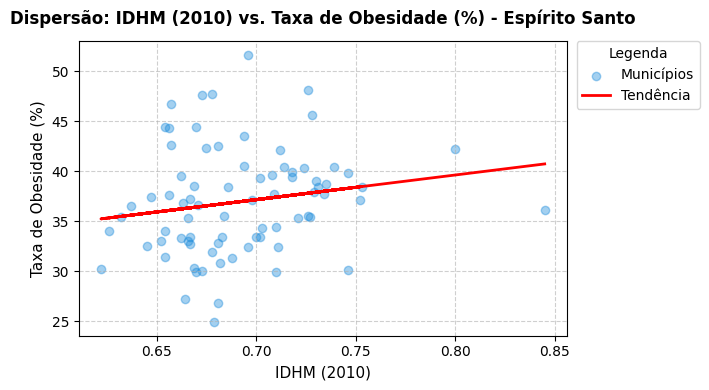

In [93]:
grafico_IDHM_Obesidade(df_consolidado_es, 'Espírito Santo')

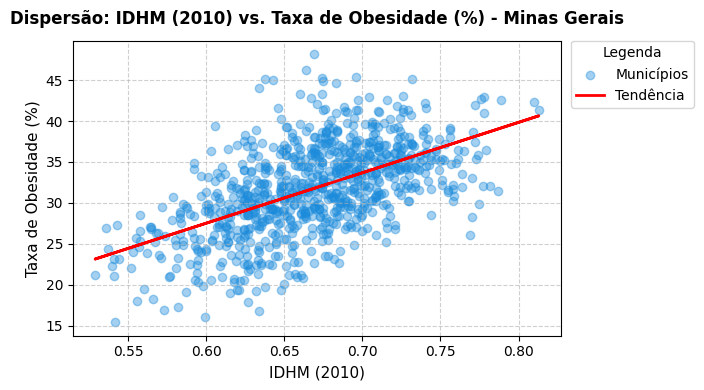

In [94]:
grafico_IDHM_Obesidade(df_consolidado_mg, 'Minas Gerais')

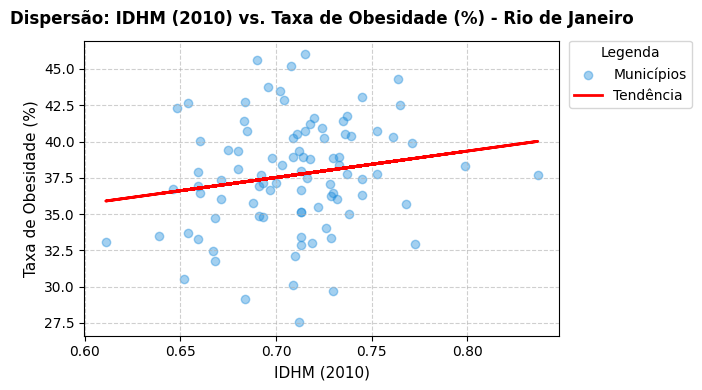

In [95]:
grafico_IDHM_Obesidade(df_consolidado_rj, 'Rio de Janeiro')

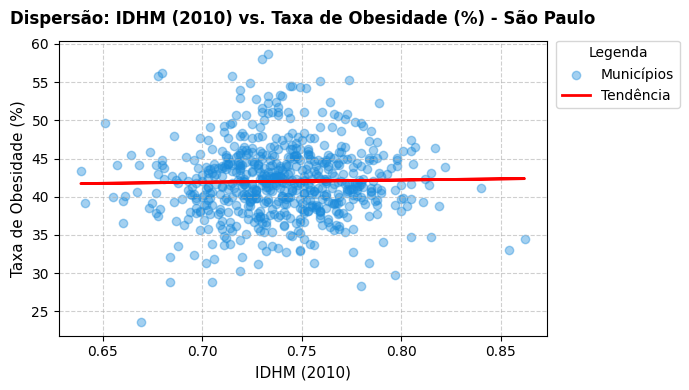

In [168]:
grafico_IDHM_Obesidade(df_tratado_sp, 'São Paulo')

### Verificação da relação dos Graus de Obesidade e do IDHM 2020 - 2025

In [97]:
analise_por_grau_obesidade_es = analise_por_grau_obesidade(df_consolidado_es, 'Espírito Santo')

analise_por_grau_obesidade_es

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Médio,21.28,9.52,5.64
Alto,21.86,9.91,6.01
Muito Alto,22.00,10.36,6.86


In [98]:
analise_por_grau_obesidade_mg = analise_por_grau_obesidade(df_consolidado_mg, 'Minas Gerais')

analise_por_grau_obesidade_mg

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Baixo,16.86,5.64,5.75
Médio,19.51,7.73,4.65
Alto,20.81,8.88,5.22
Muito Alto,22.60,11.46,7.73


In [99]:
analise_por_grau_obesidade_rj = analise_por_grau_obesidade(df_consolidado_rj, 'Rio de Janeiro')

analise_por_grau_obesidade_rj

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Médio,21.41,9.79,5.94
Alto,21.75,10.18,6.11
Muito Alto,21.83,9.92,5.98


In [167]:
analise_por_grau_obesidade_sp = analise_por_grau_obesidade(df_tratado_sp, 'São Paulo')

analise_por_grau_obesidade_sp

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Médio,23.16,11.06,7.00
Alto,23.34,11.39,7.66
Muito Alto,22.86,10.95,7.15


### Análise da evolução anual de um Grau específico de obesidade em relação as faixas de IDHM

In [101]:
evolucao_anual_grauI_mg = evolucao_anual_grau(df_consolidado_mg, 'Obesidade Grau I %', 'Minas Gerais')

evolucao_anual_grauI_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,16.24,16.49,16.16,16.32,17.38,18.58
Médio,19.15,19.37,18.84,19.19,19.77,20.77
Alto,20.49,20.81,20.09,20.48,21.06,21.95
Muito Alto,22.41,23.21,22.37,22.30,22.30,23.02


### Gráfico e tabela da Prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN 

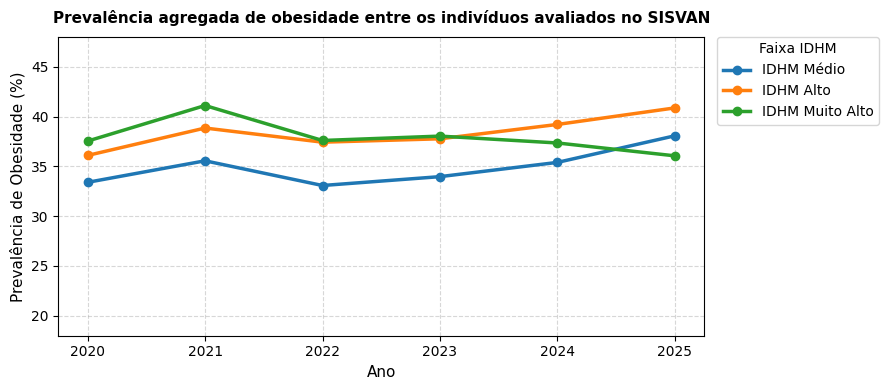

obesidade_total   Total  prevalencia %
ano  faixa_idhm                                        
2020 Médio                 10107   30261          33.40
     Alto                  23472   65018          36.10
     Muito Alto             6252   16655          37.54
2021 Médio                 16410   46142          35.56
     Alto                  29780   76658          38.85
     Muito Alto            11281   27439          41.11
2022 Médio                 21270   64294          33.08
     Alto                  53033  141673          37.43
     Muito Alto            15711   41788          37.60
2023 Médio                 25805   75960          33.97
     Alto                  67811  179545          37.77
     Muito Alto            18785   49384          38.04
2024 Médio                 25646   72441          35.40
     Alto                  78613  200495          39.21
     Muito Alto            32189   86186          37.35
2025 Médio                 37135   97556          38.07
     Alto                  98641  241348          40.87
     Muito Alto            50308  139526          36.06

In [102]:
prevalencia_agregada_es = prevalencia_agregada(df_consolidado_es)

prevalencia_agregada_es

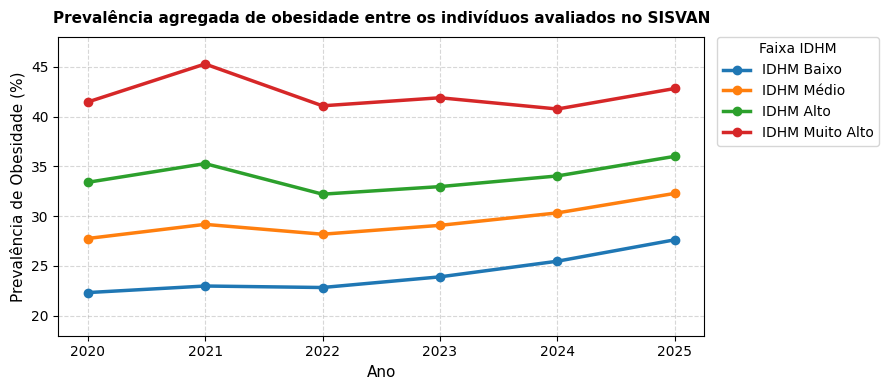

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Baixo                 22672   101522          22.33
     Médio                204260   735910          27.76
     Alto                 256339   767426          33.40
     Muito Alto            30078    72545          41.46
2021 Baixo                 25292   110013          22.99
     Médio                229578   786858          29.18
     Alto                 299976   850208          35.28
     Muito Alto            34186    75504          45.28
2022 Baixo                 31894   139638          22.84
     Médio                309167  1096580          28.19
     Alto                 400130  1242165          32.21
     Muito Alto            35310    85956          41.08
2023 Baixo                 33978   142111          23.91
     Médio                358630  1233146          29.08
     Alto                 488397  1481121          32.97
     Muito Alto            38307    91445          41.89
2024 Baixo                 37614   147595          25.48
     Médio                395330  1303541          30.33
     Alto                 554197  1627877          34.04
     Muito Alto            24413    59888          40.76
2025 Baixo                 45179   163503          27.63
     Médio                463988  1437085          32.29
     Alto                 641289  1780947          36.01
     Muito Alto            27702    64699          42.82

In [103]:
prevalencia_agregada_mg = prevalencia_agregada(df_consolidado_mg)

prevalencia_agregada_mg

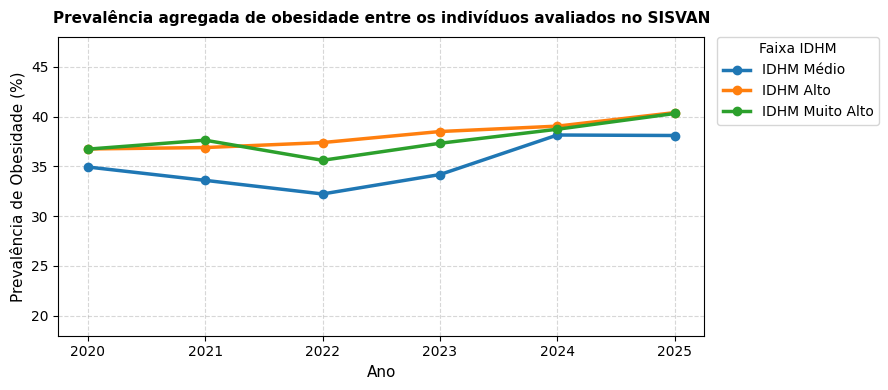

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Médio                 13000    37207          34.94
     Alto                 156523   425891          36.75
     Muito Alto             3999    10889          36.73
2021 Médio                 17838    53082          33.60
     Alto                 196836   533598          36.89
     Muito Alto             3388     9004          37.63
2022 Médio                 30077    93319          32.23
     Alto                 333369   891662          37.39
     Muito Alto             4973    13967          35.61
2023 Médio                 41731   122091          34.18
     Alto                 466743  1212285          38.50
     Muito Alto             9178    24591          37.32
2024 Médio                 56161   147226          38.15
     Alto                 572571  1466493          39.04
     Muito Alto            15892    41036          38.73
2025 Médio                 76720   201371          38.10
     Alto                 731489  1810665          40.40
     Muito Alto            19246    47745          40.31

In [104]:
prevalencia_agregada_rj = prevalencia_agregada(df_consolidado_rj)

prevalencia_agregada_rj

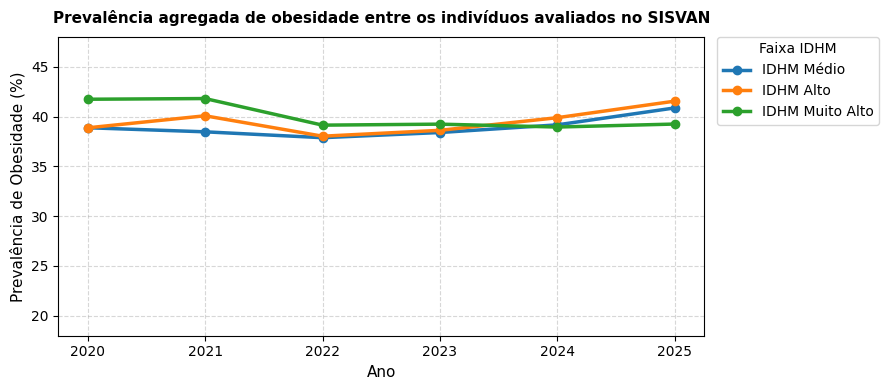

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Médio                 12801    32928          38.88
     Alto                 310905   799914          38.87
     Muito Alto           152522   365418          41.74
2021 Médio                 16372    42553          38.47
     Alto                 437466  1091405          40.08
     Muito Alto           211888   506834          41.81
2022 Médio                 28280    74649          37.88
     Alto                 648087  1704277          38.03
     Muito Alto           337937   863371          39.14
2023 Médio                 34798    90609          38.40
     Alto                 800531  2073054          38.62
     Muito Alto           444062  1131636          39.24
2024 Médio                 42172   107676          39.17
     Alto                 958270  2402030          39.89
     Muito Alto           507342  1302481          38.95
2025 Médio                 52564   128627          40.87
     Alto                1210310  2913023          41.55
     Muito Alto           626455  1595973          39.25

In [172]:
prevalencia_agregada_sp = prevalencia_agregada(df_tratado_sp)

prevalencia_agregada_sp

### Nomes dos municípios na faixa de IDHM Muito Alto

In [177]:
cidades_idhm_sp = nome_municipio_por_IDHM(df_tratado_sp, 'Muito Alto')

cidades_idhm_sp

,municipio_norm,faixa_idhm,idhm_2010
6,AGUAS DE SAO PEDRO,Muito Alto,0.854
18,AMERICANA,Muito Alto,0.811
36,ARARAQUARA,Muito Alto,0.815
46,ASSIS,Muito Alto,0.805
67,BAURU,Muito Alto,0.801
85,BOTUCATU,Muito Alto,0.800
108,CAMPINAS,Muito Alto,0.805
235,ILHA SOLTEIRA,Muito Alto,0.812
295,JUNDIAI,Muito Alto,0.822
441,PIRASSUNUNGA,Muito Alto,0.801


In [174]:
cidades_idhm_es = nome_municipio_por_IDHM(df_consolidado_es, 'Muito Alto')

cidades_idhm_es

,municipio_norm,faixa_idhm,idhm_2010
76,VILA VELHA,Muito Alto,0.800
77,VITORIA,Muito Alto,0.845


In [175]:
cidades_idhm_mg = nome_municipio_por_IDHM(df_consolidado_mg, 'Muito Alto')

cidades_idhm_mg

,municipio_norm,faixa_idhm,idhm_2010
65,BELO HORIZONTE,Muito Alto,0.810
519,NOVA LIMA,Muito Alto,0.813


In [176]:
cidades_idhm_rj = nome_municipio_por_IDHM(df_consolidado_rj, 'Muito Alto')

cidades_idhm_rj

,municipio_norm,faixa_idhm,idhm_2010
47,NITEROI,Muito Alto,0.837
